# 02 Feature family ablation (H6)

For every experiment the random forest of the modelling notebooks (same hyperparameters, same
grouped split with seed 1) is retrained

* with the full set of 42 features,
* with one of the eight feature families removed (`drop`),
* optionally with only one family (`only`, set `RUN_ONLY = True`).

Every configuration is evaluated in domain (held out sources of the training capture) and on
the university capture. The difference to the full set on the university capture is tested with
a paired bootstrap over source addresses, Holm corrected over the eight families per experiment.

H6 is supported if every `drop` configuration scores below the full set; it is refuted if at
least one `drop` configuration matches or exceeds it.

Runtime: (1 + 8 [+ 8]) random forest fits per experiment and label, about 1 to 3 minutes each.
Results are cached per experiment in `results/ablation/`, so an interrupted run can continue.

In [1]:
import sys, pathlib, importlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
sys.path.append(str(pathlib.Path.cwd()))  # the notebooks live in code/analysis
import analysis_utils as au
importlib.reload(au)

RESULTS = pathlib.Path('results')
FIGURES = RESULTS / 'figures'
FIGURES.mkdir(parents=True, exist_ok=True)

EXPS = au.available_experiments()
print('experiments with exported artifacts:', EXPS)
missing = [e for e in au.EXPERIMENTS if e not in EXPS]
if missing:
    print('NOT YET RERUN (no artifacts):', missing)

experiments with exported artifacts: ['E1_apple_same', 'E2_apple_diff', 'E3_samsung_same', 'E4_samsung_diff', 'E5_mixed_same', 'E6_mixed_diff']


In [2]:
from sklearn.metrics import f1_score, matthews_corrcoef

LABELS = ['group_label_multi']        # add 'group_label' to repeat it on the binary task
SPLIT_GROUPED = True                  # the honest in domain estimate, as in the design
RUN_ONLY = False                      # also train with a single family
N_BOOT = 1000
OUT = RESULTS / 'ablation'
OUT.mkdir(exist_ok=True)

def configurations(feats):
    yield 'full', feats
    for fam, cols in au.FEATURE_FAMILIES.items():
        yield f'drop: {fam}', [f for f in feats if f not in cols]
    if RUN_ONLY:
        for fam, cols in au.FEATURE_FAMILIES.items():
            yield f'only: {fam}', [f for f in feats if f in cols]

In [3]:
for e in EXPS:
    for label in LABELS:
        cache = OUT / f'{e}__{label}.parquet'
        if cache.exists():
            print('cached:', cache.name)
            continue
        tr = au.load_frame(e, 'train')
        ev = au.load_frame(e, 'eval')
        feats = au.feature_columns(tr)
        tr_idx, te_idx = au.grouped_split(tr, tr[label], grouped=SPLIT_GROUPED)
        fit_df, test_df = tr.iloc[tr_idx], tr.iloc[te_idx]
        transfer = pd.DataFrame({'y_true': ev[label].to_numpy(), 'source': ev['source'].to_numpy()})
        indomain = pd.DataFrame({'y_true': test_df[label].to_numpy(), 'source': test_df['source'].to_numpy()})
        for name, cols in configurations(feats):
            model = au.make_random_forest().fit(fit_df[cols], fit_df[label])
            indomain[name] = model.predict(test_df[cols])
            transfer[name] = model.predict(ev[cols])
            print(f'{e} {label} {name:35s} in domain {f1_score(indomain.y_true, indomain[name], average="macro"):.3f}'
                  f'  transfer {f1_score(transfer.y_true, transfer[name], average="macro"):.3f}')
            del model
        indomain.assign(frame='indomain').pipe(lambda d: pd.concat([d, transfer.assign(frame='transfer')])) \
            .to_parquet(cache, index=False)

E1_apple_same group_label_multi full                                in domain 0.908  transfer 0.383


E1_apple_same group_label_multi drop: PDU role                      in domain 0.904  transfer 0.351


E1_apple_same group_label_multi drop: Channel and PHY               in domain 0.907  transfer 0.418


E1_apple_same group_label_multi drop: Payload shape                 in domain 0.905  transfer 0.407


E1_apple_same group_label_multi drop: Burst microstructure          in domain 0.914  transfer 0.420


E1_apple_same group_label_multi drop: Joint activity                in domain 0.909  transfer 0.381


... (44 outputs left out)

E6_mixed_diff group_label_multi drop: Joint activity                in domain 0.913  transfer 0.519


E6_mixed_diff group_label_multi drop: Payload dynamics              in domain 0.912  transfer 0.524


E6_mixed_diff group_label_multi drop: Timing                        in domain 0.876  transfer 0.495


E6_mixed_diff group_label_multi drop: Shape and session span        in domain 0.905  transfer 0.457


## Scores and paired tests against the full set

In [4]:
rows = []
for e in EXPS:
    for label in LABELS:
        d = pd.read_parquet(OUT / f'{e}__{label}.parquet')
        configs = [c for c in d.columns if c not in ('y_true', 'source', 'frame')]
        for frame, f in d.groupby('frame'):
            b = au.cluster_bootstrap(f['source'], f['y_true'], {c: f[c] for c in configs}, 'macro_f1', N_BOOT)
            for c in configs:
                r = dict(exp=au.exp_name(e), label=label, frame=frame, config=c,
                         macro_f1=f1_score(f['y_true'], f[c], average='macro', zero_division=0),
                         mcc=matthews_corrcoef(f['y_true'], f[c]),
                         **{f'f1_{k}': v for k, v in enumerate(f1_score(f['y_true'], f[c], average=None, zero_division=0))})
                if c != 'full':
                    r.update(au.paired_bootstrap_test(b, c, 'full'))
                rows.append(r)
abl = pd.DataFrame(rows)
abl['delta_vs_full'] = abl['macro_f1'] - abl.groupby(['exp', 'label', 'frame'])['macro_f1'].transform(
    lambda s: s[abl.loc[s.index, 'config'] == 'full'].iloc[0])
abl['p_holm'] = np.nan
for _, idx in abl[abl['config'] != 'full'].groupby(['exp', 'label', 'frame']).groups.items():
    abl.loc[idx, 'p_holm'] = au.holm(abl.loc[idx, 'p_boot'])
abl.to_csv(RESULTS / 'ablation_feature_families.csv', index=False)
abl[abl['frame'] == 'transfer'].round(3)

,exp,label,frame,config,macro_f1,mcc,f1_0,f1_1,f1_2,diff_mean,ci_low,ci_high,p_boot,delta_vs_full,p_holm
9,E1 apple same,group_label_multi,transfer,full,0.383,0.215,0.922,0.227,0.000,NaN,NaN,NaN,NaN,0.000,NaN
10,E1 apple same,group_label_multi,transfer,drop: PDU role,0.351,0.195,0.886,0.167,0.000,-0.032,-0.044,-0.021,0.000,-0.032,0.000
11,E1 apple same,group_label_multi,transfer,drop: Channel and PHY,0.418,0.252,0.935,0.317,0.000,0.035,0.026,0.043,0.000,0.035,0.000
12,E1 apple same,group_label_multi,transfer,drop: Payload shape,0.407,0.219,0.925,0.297,0.000,0.024,0.016,0.033,0.000,0.024,0.000
13,E1 apple same,group_label_multi,transfer,drop: Burst microstructure,0.420,0.208,0.930,0.330,0.000,0.037,0.025,0.049,0.000,0.037,0.000
14,E1 apple same,group_label_multi,transfer,drop: Joint activity,0.381,0.209,0.918,0.225,0.000,-0.002,-0.005,0.002,0.412,-0.002,0.824
15,E1 apple same,group_label_multi,transfer,drop: Payload dynamics,0.385,0.184,0.901,0.253,0.000,0.002,-0.004,0.008,0.522,0.002,0.824
16,E1 apple same,group_label_multi,transfer,drop: Timing,0.405,0.247,0.916,0.178,0.121,0.022,0.011,0.036,0.000,0.022,0.000
17,E1 apple same,group_label_multi,transfer,drop: Shape and session span,0.412,0.171,0.905,0.330,0.000,0.028,0.017,0.042,0.000,0.029,0.000
27,E2 apple diff,group_label_multi,transfer,full,0.490,0.344,0.969,0.295,0.206,NaN,NaN,NaN,NaN,0.000,NaN


In [5]:
# H6 verdict per experiment: does any 'drop' configuration match or beat the full set?
drop = abl[abl['config'].str.startswith('drop')]
verdict = (drop.groupby(['exp', 'label', 'frame'])
           .apply(lambda g: pd.Series({
               'best_drop': g.loc[g['delta_vs_full'].idxmax(), 'config'],
               'best_drop_delta': g['delta_vs_full'].max(),
               'drops_at_or_above_full': int((g['delta_vs_full'] >= 0).sum()),
               'drops_significantly_below_full': int(((g['delta_vs_full'] < 0) & (g['p_holm'] < 0.05)).sum()),
               'H6_supported': bool((g['delta_vs_full'] < 0).all())}))
           .reset_index())
verdict

C:\Users\thoma\AppData\Local\Temp\ipykernel_7540\2123833732.py:4: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda g: pd.Series({


,exp,label,frame,best_drop,best_drop_delta,drops_at_or_above_full,drops_significantly_below_full,H6_supported
0,E1 apple same,group_label_multi,indomain,drop: Payload dynamics,0.007037,3,1,False
1,E1 apple same,group_label_multi,transfer,drop: Burst microstructure,0.037033,6,1,False
2,E2 apple diff,group_label_multi,indomain,drop: Payload shape,0.005741,5,1,False
3,E2 apple diff,group_label_multi,transfer,drop: Joint activity,0.017510,4,3,False
4,E3 samsung same,group_label_multi,indomain,drop: PDU role,0.001894,2,1,False
5,E3 samsung same,group_label_multi,transfer,drop: Timing,0.049059,6,1,False
6,E4 samsung diff,group_label_multi,indomain,drop: Burst microstructure,0.001601,6,1,False
7,E4 samsung diff,group_label_multi,transfer,drop: Joint activity,0.069304,6,1,False
8,E5 mixed same,group_label_multi,indomain,drop: Payload dynamics,0.002407,3,1,False
9,E5 mixed same,group_label_multi,transfer,drop: Burst microstructure,0.134682,6,1,False


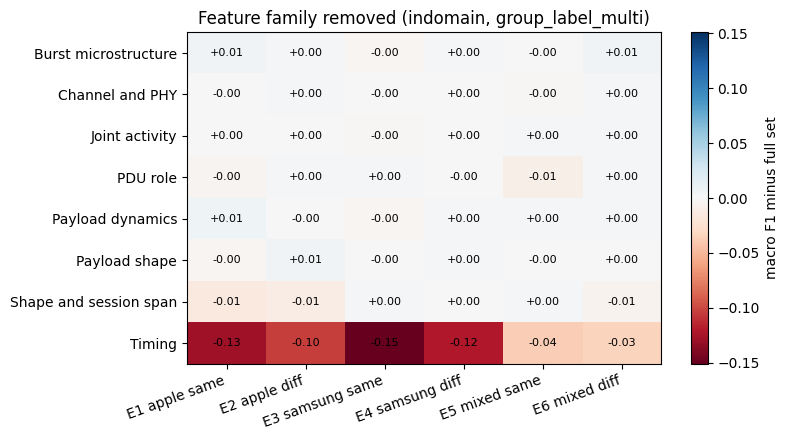

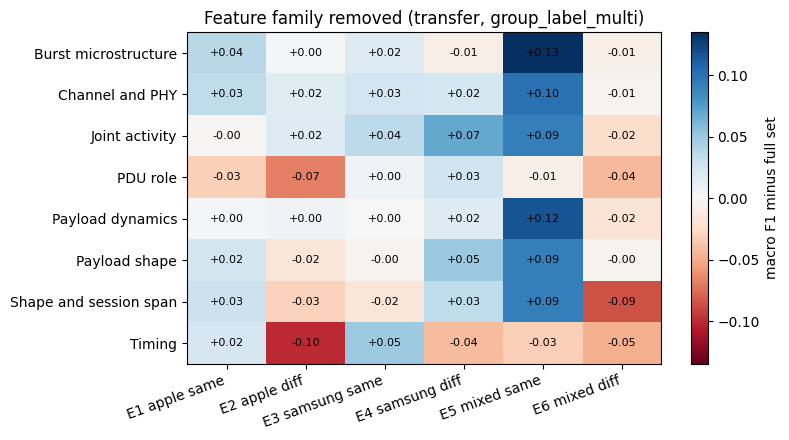

In [6]:
# Heatmap: change in macro F1 when a family is removed
for frame in ['indomain', 'transfer']:
    h = (drop[(drop['frame'] == frame) & (drop['label'] == LABELS[0])]
         .pivot(index='config', columns='exp', values='delta_vs_full'))
    h.index = h.index.str.replace('drop: ', '')
    fig, ax = plt.subplots(figsize=(8, 4.5))
    lim = np.nanmax(np.abs(h.values)) or 0.01
    im = ax.imshow(h.values, cmap='RdBu', vmin=-lim, vmax=lim, aspect='auto')
    ax.set_xticks(range(h.shape[1])); ax.set_xticklabels(h.columns, rotation=20, ha='right')
    ax.set_yticks(range(h.shape[0])); ax.set_yticklabels(h.index)
    for i in range(h.shape[0]):
        for j in range(h.shape[1]):
            ax.text(j, i, f'{h.values[i, j]:+.2f}', ha='center', va='center', fontsize=8)
    fig.colorbar(im, label='macro F1 minus full set')
    ax.set_title(f'Feature family removed ({frame}, {LABELS[0]})')
    plt.tight_layout(); plt.savefig(FIGURES / f'fig_ablation_{frame}.pdf'); plt.show()